# Student Performance Data Analysis

## 1. Introduction

This project explores student performance in Mathematics using a public dataset from the UCI Machine Learning Repository. The analysis uses Python, pandas, NumPy, and Matplotlib to investigate patterns in students' final grades and their relationships with study time, school absences, and earlier grades.

### Project objectives

- Explore the structure and quality of the dataset.
- Summarize final Mathematics grades.
- Compare average grades across study-time groups.
- Investigate the relationship between absences and final grades.
- Examine the relationship between earlier grades and final performance.
- Communicate findings through visualizations and descriptive statistics.

### Research questions

1. How are final Mathematics grades distributed?
2. How do average final grades differ across study-time categories?
3. What relationship, if any, exists between school absences and final grades?
4. How strongly are earlier-period grades associated with final grades?

### Tools

- Python
- pandas
- NumPy
- Matplotlib
- Jupyter Notebook

### Dataset source

UCI Machine Learning Repository: Student Performance dataset.

https://archive.ics.uci.edu/dataset/320/student+performance

The dataset is used under the Creative Commons Attribution 4.0 International (CC BY 4.0) licence. The analysis focuses on the Mathematics dataset (`student-mat.csv`).


In [1]:
import sys
print("Python is connected!")
print(sys.executable)

Python is connected!
c:\Users\PC\anaconda3\python.exe


## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

pandas: 2.2.2
NumPy: 1.26.4
Matplotlib: 3.9.2


## 3. Load the Dataset

In [2]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


## 4. Data Exploration and Quality Checks

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [5]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [6]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### 5.1 Distribution of Final Mathematics Grades

This section summarizes students' final Mathematics grades using the mean, median, highest, and lowest scores.

In [7]:
print("Average final grade:", df["G3"].mean())
print("Median final grade:", df["G3"].median())
print("Highest final grade:", df["G3"].max())
print("Lowest final grade:", df["G3"].min())

Average final grade: 10.415189873417722
Median final grade: 11.0
Highest final grade: 20
Lowest final grade: 0


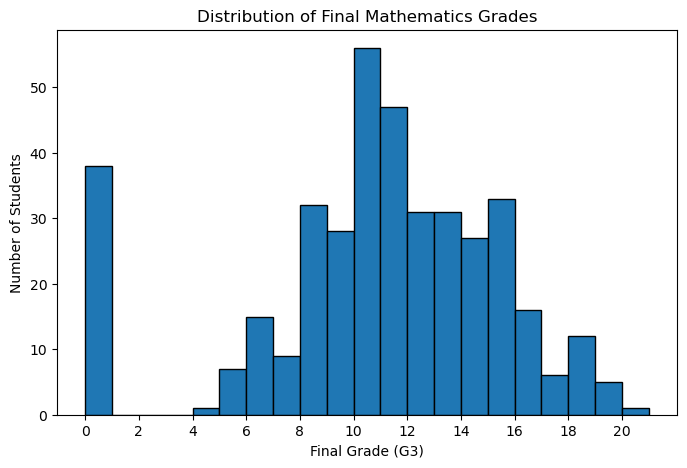

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(df["G3"], bins=range(0, 22), edgecolor="black")

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21, 2))

plt.show()

### 5.2 Study Time and Final Mathematics Grades

This section compares average final Mathematics grades across different study-time groups to explore whether study time is associated with academic performance.

In [9]:
study_results = df.groupby("studytime")["G3"].mean()

print(study_results)

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


In [10]:
absence_results = df.groupby(
    pd.cut(df["absences"], bins=[-1, 0, 5, 10, 100],
           labels=["0 absences", "1–5", "6–10", "11+"])
)["G3"].agg(["mean", "count"])

print(absence_results)

                 mean  count
absences                    
0 absences   8.443478    115
1–5         11.649254    134
6–10        11.400000     80
11+         10.151515     66


C:\Users\PC\AppData\Local\Temp\ipykernel_24872\3208162367.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  absence_results = df.groupby(


In [11]:
absence_results = df.groupby(
    pd.cut(
        df["absences"],
        bins=[-1, 0, 5, 10, 100],
        labels=["0 absences", "1–5", "6–10", "11+"]
    ),
    observed=False
)["G3"].agg(["mean", "count"])

print(absence_results)

                 mean  count
absences                    
0 absences   8.443478    115
1–5         11.649254    134
6–10        11.400000     80
11+         10.151515     66


### 5.3 School Absences and Final Mathematics Grades

This section examines average final Mathematics grades across absence groups and investigates the relationship between the number of absences and final grades.

In [12]:
correlation = df["absences"].corr(df["G3"])

print("Correlation between absences and final grade:",
      round(correlation, 3))


Correlation between absences and final grade: 0.034


## Finding 3: Absences and Final Mathematics Grades

The Pearson correlation between school absences and final
Mathematics grades (G3) was 0.034, indicating a very weak
positive linear relationship that is close to zero.

This suggests that absences alone have little linear
association with final grades in this dataset. However,
this does not establish that absences have no effect.
Other factors and non-linear patterns may be relevant.

The results are descriptive and should not be interpreted
as evidence of causation.

In [13]:
grade_correlations = df[["G1", "G2", "G3"]].corr()

print(grade_correlations.round(3))

       G1     G2     G3
G1  1.000  0.852  0.801
G2  0.852  1.000  0.905
G3  0.801  0.905  1.000


## Finding 4: Earlier Grades and Final Performance

The correlation between first-period grades (G1) and final
grades (G3) was 0.801, indicating a strong positive
relationship.

The correlation between second-period grades (G2) and
final grades (G3) was 0.905, indicating a very strong
positive relationship.

G2 had the stronger association with final performance.
This suggests that earlier academic performance may be
useful for understanding final grades. However, correlation
does not prove causation, and these results alone do not
establish predictive accuracy on unseen students.

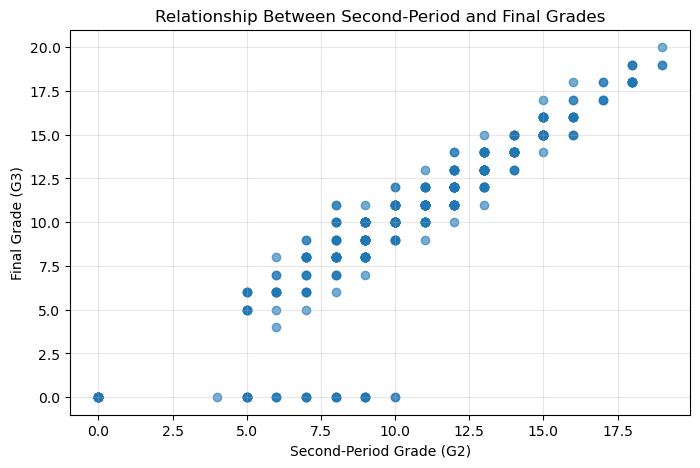

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(df["G2"], df["G3"], alpha=0.6)

plt.title("Relationship Between Second-Period and Final Grades")
plt.xlabel("Second-Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.grid(alpha=0.3)

plt.show()

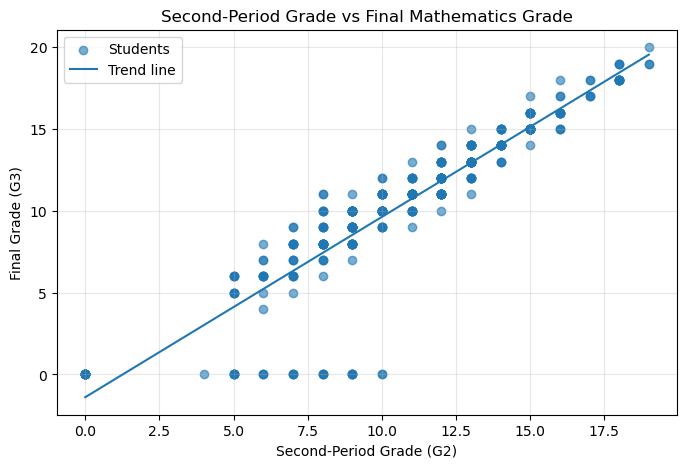

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(df["G2"], df["G3"], alpha=0.6, label="Students")

# Calculate and draw the trend line
slope, intercept = np.polyfit(df["G2"], df["G3"], 1)

x = np.linspace(df["G2"].min(), df["G2"].max(), 100)
y = slope * x + intercept

plt.plot(x, y, label="Trend line")

plt.title("Second-Period Grade vs Final Mathematics Grade")
plt.xlabel("Second-Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 6. Conclusion

This project explored student performance in Mathematics using the UCI Student Performance dataset.

The analysis found a strong positive relationship between earlier grades and final Mathematics performance. In particular, the correlation between second-period grades (G2) and final grades (G3) was 0.905, while the correlation between first-period grades (G1) and final grades (G3) was 0.801.

Average final grades also differed across study-time groups, although the differences were not perfectly consistent across all categories. The relationship between school absences and final grades was very weak in linear terms, with a correlation of 0.034.

These findings describe patterns in this dataset and do not establish cause and effect. Other factors may also contribute to students' academic performance.

Overall, this project provided practical experience in data loading, data exploration, descriptive statistics, correlation analysis, and data visualization using Python.